Los equipos de marketing de instituciones financieras necesitan entender qué tipos de clientes tienen, para diseñar productos, comunicaciones y beneficios que sean relevantes para cada grupo. No todos los clientes usan la tarjeta de crédito de la misma manera: algunos la usan para compras grandes esporádicas, otros para gastos cotidianos pequeños, otros solo sacan adelantos en efectivo, y otros apenas la usan.

El dataset contiene el comportamiento de uso de tarjetas de crédito de clientes de un banco durante seis meses: saldo promedio, frecuencia de compras, montos de compras únicas versus en cuotas, frecuencia de adelantos de efectivo, límite de crédito, y tasa de pago. El objetivo es descubrir grupos de clientes con patrones de comportamiento similares, sin que exista una respuesta predefinida de antemano sobre cuántos grupos hay ni cuáles son.

La descripción anterior corresponde a un problema de clustering, en particular, aprendizaje no supervisado. Comenzamos descargando la base de datos de Kaggle y haciendo una primera exploración.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('CC GENERAL.csv')
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


Hay 8950 instancias, correspondientes a la misma cantidad de clientes (CUST_ID es una clave). Tomamos más información sobre el resto de variables de la página de Kaggle donde se puede descargar este dataset: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata:

1) CUST_ID : Identification of Credit Card holder (Categorical)
2) BALANCE : Balance amount left in their account to make purchases
3) BALANCE_FREQUENCY : How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated)
4) PURCHASES : Amount of purchases made from account
5) ONEOFF_PURCHASES : Maximum purchase amount done in one-go
6) INSTALLMENTS_PURCHASES : Amount of purchase done in installment
7) CASH_ADVANCE : Cash in advance given by the user
8) PURCHASES_FREQUENCY : How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased)
9) ONEOFFPURCHASESFREQUENCY : How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased)
10) PURCHASESINSTALLMENTSFREQUENCY : How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done)
11) CASHADVANCEFREQUENCY : How frequently the cash in advance being paid
12) CASHADVANCETRX : Number of Transactions made with "Cash in Advanced"
13) PURCHASES_TRX : Numbe of purchase transactions made
14) CREDIT_LIMIT : Limit of Credit Card for user
15) PAYMENTS : Amount of Payment done by user
16) MINIMUM_PAYMENTS : Minimum amount of payments made by user
17) PRCFULLPAYMENT : Percent of full payment paid by user
18) TENURE : Tenure of credit card service for user

Se informa en la página que esta base de datos reúne información sobre la conducta financiera de dueños de tarjetas de crédito a lo largo de 6 meses.

Comenzamos verificando que CUST_ID es realmente una clave.

In [ ]:
len(df['CUST_ID'].unique()) #efectivamente, hay la misma cantidad de ids únicos que de filas, por lo que estos no se repiten.
#Por lo tanto, cada fila corresponde a un cliente de banco diferente.

8950

Veamos primero los tipos de dato de cada atributo:

In [ ]:
print([type(df[columna][0]) for columna in df.columns]) #son todos float64 excepto CUST_ID, que es string.
for columna in df.columns:
    print(columna, " ",df[columna].isna().sum()) #los nans son 313 en la columna minimum_payments y 1 en credit_limit

[<class 'str'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.int64'>, <class 'numpy.int64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.float64'>, <class 'numpy.int64'>]
CUST_ID   0
BALANCE   0
BALANCE_FREQUENCY   0
PURCHASES   0
ONEOFF_PURCHASES   0
INSTALLMENTS_PURCHASES   0
CASH_ADVANCE   0
PURCHASES_FREQUENCY   0
ONEOFF_PURCHASES_FREQUENCY   0
PURCHASES_INSTALLMENTS_FREQUENCY   0
CASH_ADVANCE_FREQUENCY   0
CASH_ADVANCE_TRX   0
PURCHASES_TRX   0
CREDIT_LIMIT   1
PAYMENTS   0
MINIMUM_PAYMENTS   313
PRC_FULL_PAYMENT   0
TENURE   0


Ya que todos los atributos menos la clave son numéricos, tomamos mediciones estadísticas para saber en qué rangos estamos trabajando.

In [10]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


En un primer análisis, vemos que hay clientes con mucho dinero restante y otros que lo gastaron todo, lo cual es esperable (el mínimo y el máximo de balance). Vemos un percentil 50 de ese atributo en 873, percentil 75 en 2054 y máximo en 19.043. Este súbito crecimiento en los últimos valores refleja que hay un pequeño grupo de personas con mucho dinero restante. En el atributo balance frequency vemos que algunas personas no vieron actualizado su balance (no gastaron), pero la amplia mayoría hacen gastos muy seguido (el percentil 25 ya es casi 0,9 y el 50 es 1, el máximo posible). En purchases frequency vemos valores muy diversos, ya que el desvío estándar es bastante alto (40% de la longitud del rango de valores posibles). 

Como Kaggle informa que esta base de datos representa el comportamiento de los clientes durante 6 meses, variables como purchases o los conteos "TRX" son acumulados sobre ese período, mientras que balance representa sólo la situación actual de la cuenta del cliente. Por eso, calcularemos algunos promedios. Asumimos que se deben calcular sobre 6 meses si la tenure (antigüedad del cliente) es igual o mayor y sobre la antigüedad si es menor. Sin embargo, notamos en la descripción hecha abajo que la tenure está siempre entre 6 y 12 meses, por lo que simplemente podemos dividir por 6.

Por otro lado, aunque ONEOFF_PURCHASES supuestamente es un monto máximo en lugar de una suma de montos totales, lo verificamos:

In [4]:
diff = df['PURCHASES'] - (df['ONEOFF_PURCHASES'] + df['INSTALLMENTS_PURCHASES'])
df['DIFF_ONEOFF_INSTALLMENT'] = df['PURCHASES'] - (df['ONEOFF_PURCHASES'] + df['INSTALLMENTS_PURCHASES'])
print(diff.describe())
diff[np.abs(diff) > 0.5] #esto sólo ocurre en 19 casos, por lo que ONEOFF_PURCHASES funciona casi siempre como un total, esté definido así o no
#Lo conservamos como nuevo atributo por si nos sirve para compararlo con otros.

count    8.950000e+03
mean    -3.001821e-01
std      9.753439e+00
min     -6.000000e+02
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      7.275958e-12
dtype: float64


510     -88.98
745     -47.26
908     -49.00
1458    -22.00
3987    -33.33
4682    -20.00
5231   -402.70
5356    -34.72
5737    -66.95
5845    -47.00
5846    -93.93
5967   -298.79
6535    -30.00
6711    -47.50
6790   -227.30
6803   -284.95
6857   -600.00
8183    -22.22
8834   -270.00
dtype: float64

In [5]:
df['AVG_PURCHASES'] = df['PURCHASES']/6
df['AVG_INSTALLMENTS_PURCHASES'] = df['INSTALLMENTS_PURCHASES']/6
df['AVG_ONEOFF_PURCHASES'] = df['ONEOFF_PURCHASES']/6 #lo conservamos sabiendo que puede estar distorsionado en los 19 casos vistos.
df['AVG_PURCHASES_TRX'] = df['PURCHASES_TRX']/6
df['AVG_CASH_ADVANCE_TRX'] = df['CASH_ADVANCE_TRX']/6
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,...,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,DIFF_ONEOFF_INSTALLMENT,AVG_PURCHASES,AVG_INSTALLMENTS_PURCHASES,AVG_ONEOFF_PURCHASES,AVG_PURCHASES_TRX,AVG_CASH_ADVANCE_TRX
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,...,8950.000000,8637.000000,8950.000000,8950.000000,8.950000e+03,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,...,1733.143852,864.206542,0.153715,11.517318,-3.001821e-01,167.200806,68.511274,98.739562,2.451639,0.541471
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,...,2895.063757,2372.446607,0.292499,1.338331,9.753439e+00,356.105797,150.723019,276.647986,4.142942,1.137441
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.019163,0.000000,6.000000,-6.000000e+02,0.000000,0.000000,0.000000,0.000000,0.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,...,383.276166,169.123707,0.000000,12.000000,0.000000e+00,6.605833,0.000000,0.000000,0.166667,0.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,...,856.901546,312.343947,0.000000,12.000000,0.000000e+00,60.213333,14.833333,6.333333,1.166667,0.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,...,1901.134317,825.485459,0.142857,12.000000,0.000000e+00,185.021667,78.106250,96.234167,2.833333,0.666667
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,...,50721.483360,76406.207520,1.000000,12.000000,7.275958e-12,8173.261667,3750.000000,6793.541667,59.666667,20.500000


Vamos a explorar posibles relaciones entre todos los atributos de promedio y los que representan un índice entre 0 y 1.

In [6]:
df_filtered = df[['BALANCE_FREQUENCY','PURCHASES_FREQUENCY','ONEOFF_PURCHASES_FREQUENCY','PURCHASES_INSTALLMENTS_FREQUENCY','CASH_ADVANCE_FREQUENCY','PRC_FULL_PAYMENT','AVG_PURCHASES','AVG_INSTALLMENTS_PURCHASES','AVG_ONEOFF_PURCHASES','AVG_PURCHASES_TRX','AVG_CASH_ADVANCE_TRX']]

c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating ins

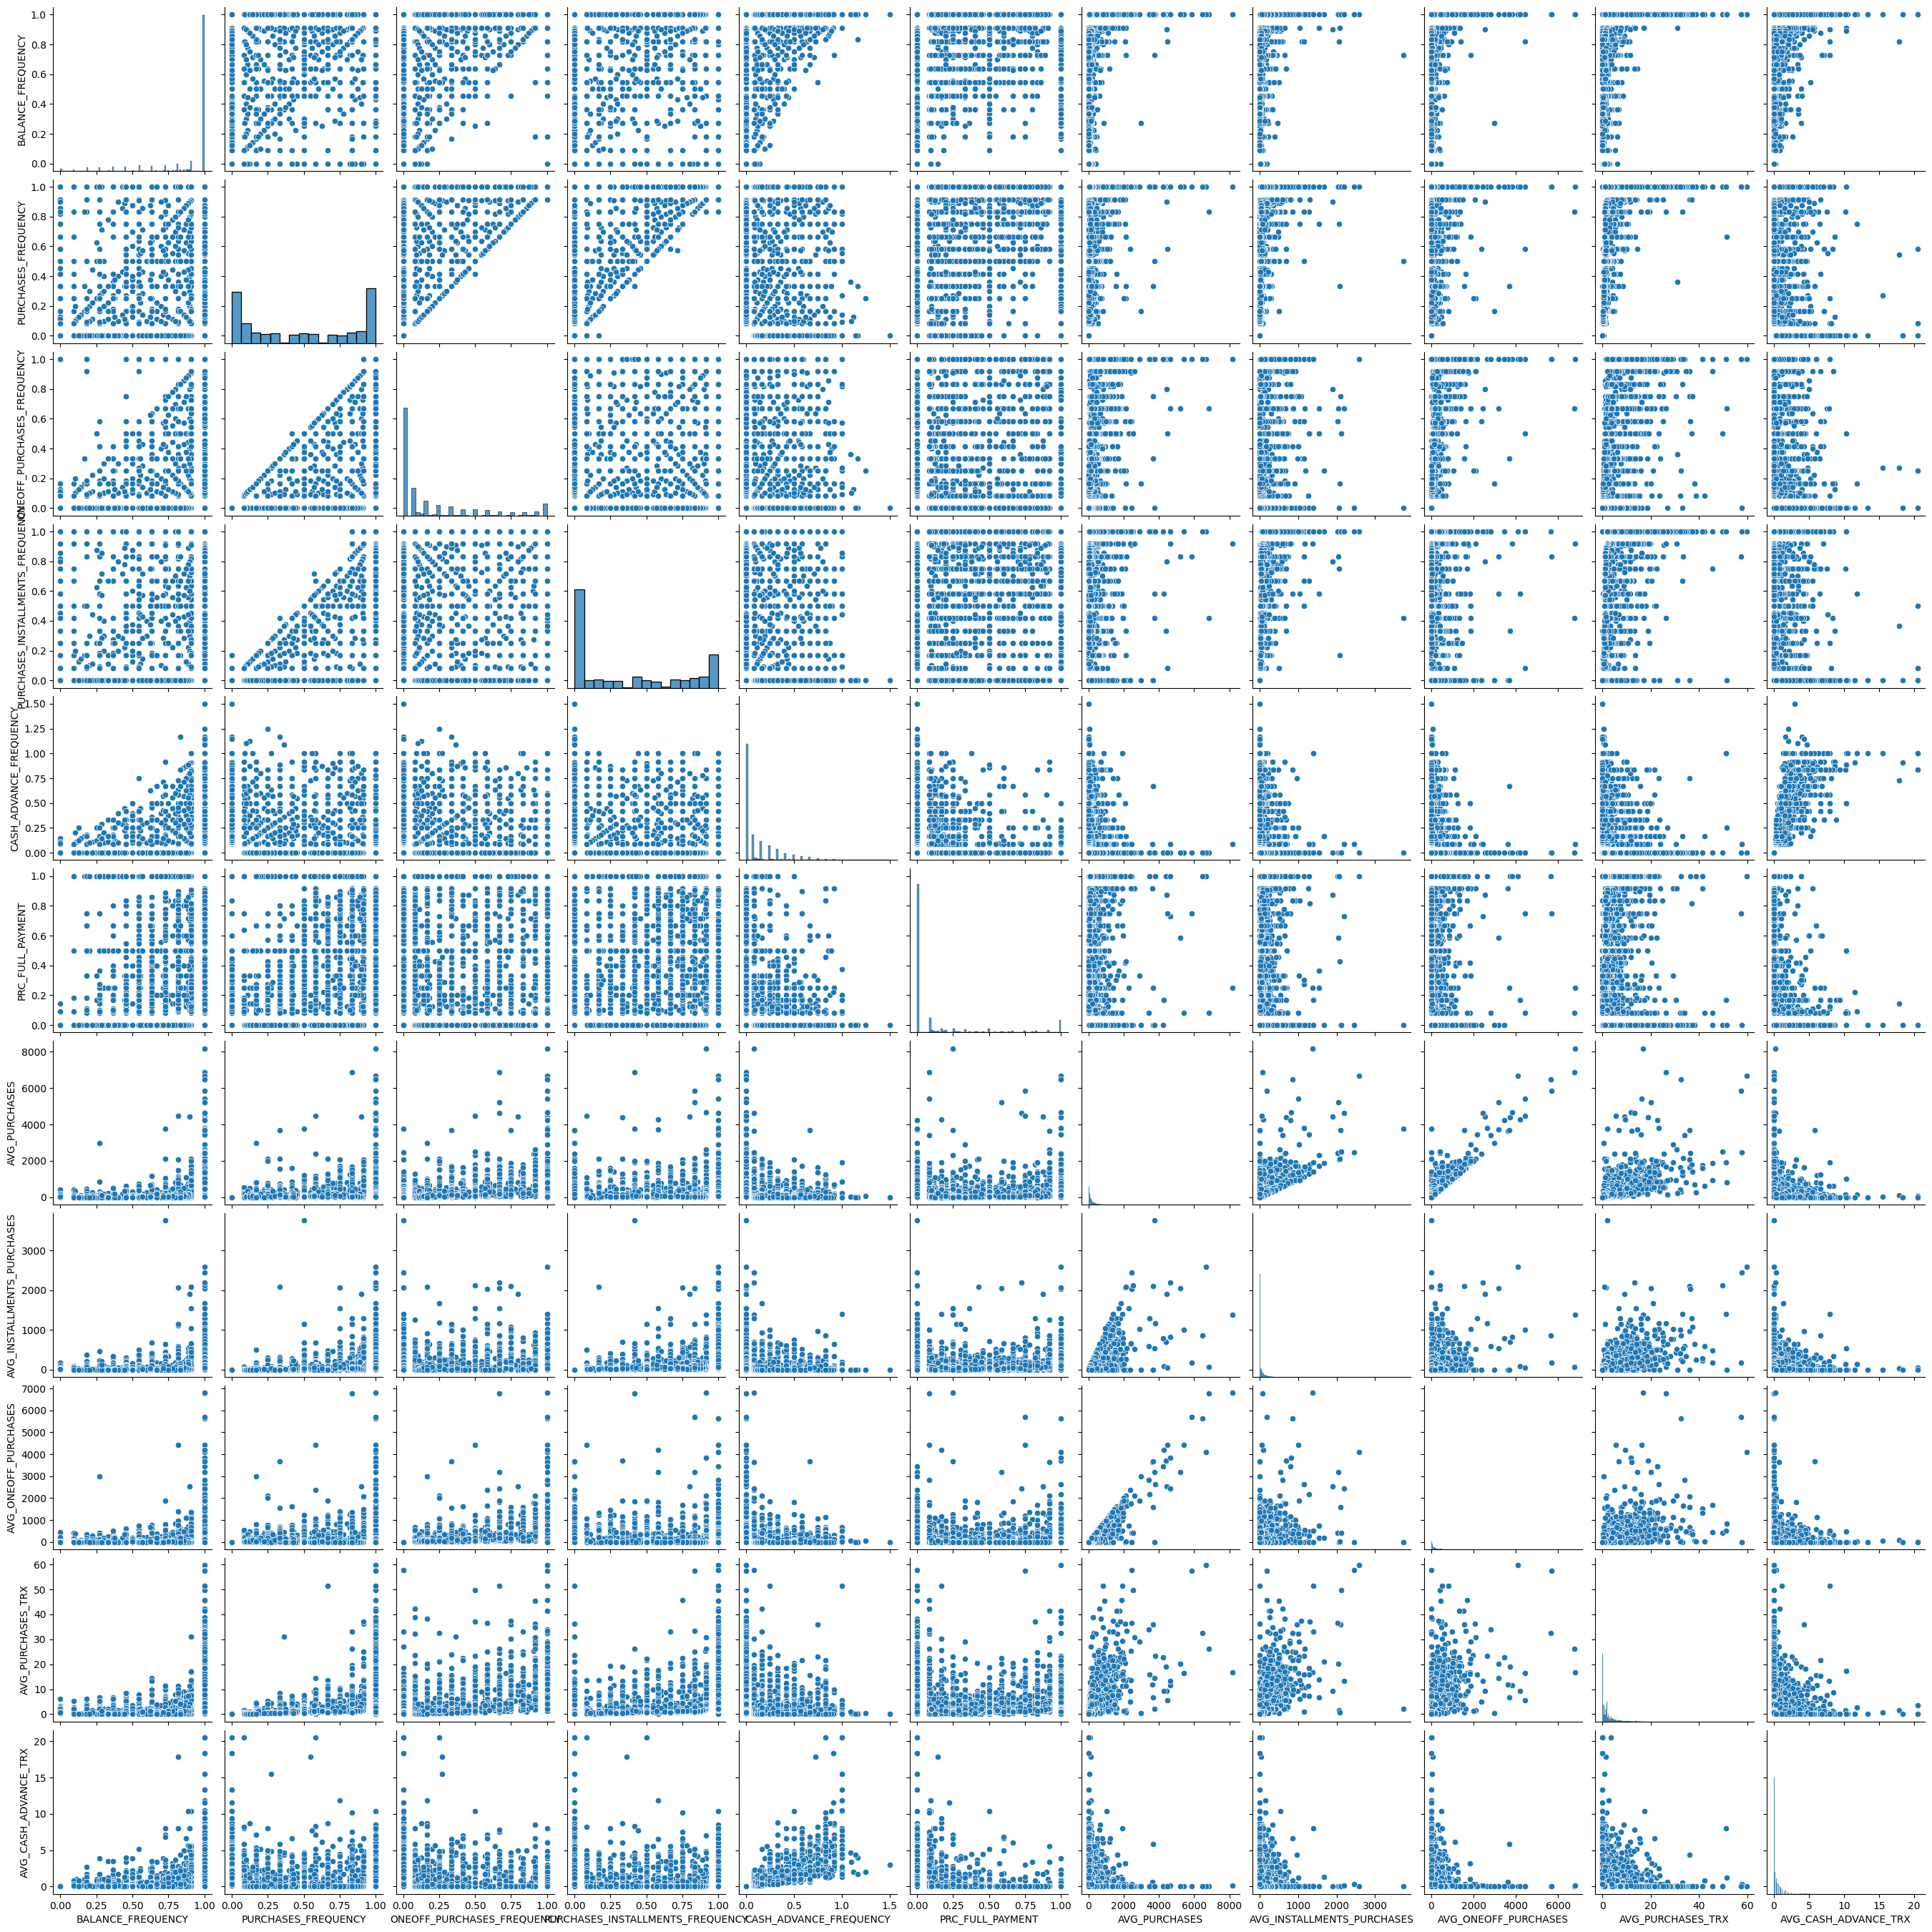

In [6]:
sns.pairplot(df_filtered)

En este gráfico observamos muy pocos casos de correlación clara entre pares de variables. Puntualmente, se puede ver que hay aproximadamente una correlación lineal de avg_purchases con avg_oneoff_purchases y con avg_installment_purchases. En otros casos, se puede ver que una variable acota superiormente a otra pero eso se deduce de sus definiciones (por ejemplo, purchases_frequency es cota superior de oneoff_purchases_frequency, que representa una parte de las compras totales). En la diagonal podemos ver que balance_frequency está casi siempre cerca de 1, es decir que la gran mayoría de clientes hacen gastos muy seguido. Luego, este no parece ser un buen criterio para definir nuestros clusters (o bien un posible cluster sería el de aquellos que no gastan tan seguido). Algo similar pasa con prc_full_payment (la gran mayoría de clientes paga muy pocas veces el monto total de la tarjeta). En la última fila se aprecia que loc clientes con alta cantidad de pedidos de efectivo adelantado gastan poco (avg_purchases,avg_installment_purchases y avg_oneoff_purchases). Estimamos que si piden muchos adelantos eso indica poca capacidad de compra. Por lo demás, se observa que unas variables acotan superiormente a otras y muchos casos sin ninguna correlación (puntos dispersos en todo el gráfico).

Queremos estudiar si hay patrones diferentes de acuerdo a la clase socioeconómica de los usuarios. Para eso queremos estimar sus ingresos mensuales. Como tenemos dos datos que no corresponden al mismo período (balance, que es actual, y purchases que es un acumulado de seis meses), estimaremos el dinero con el que vive el usuario sumando su balance con el AVG_PURCHASES (de modo que aproximamos este valor sumando lo que le quedó con lo que se supone gastó el último mes). Otro valor interesante para estudiar es cuánto gastan los usuarios en promedio con cada compra. 

In [15]:
df['EST_INCOME'] = df['BALANCE'] + df['AVG_PURCHASES']
df['AVG_PURCHASE_COST'] = np.where(df['PURCHASES_TRX'] > 0, df['PURCHASES']/df['PURCHASES_TRX'],0)

In [16]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,...,PRC_FULL_PAYMENT,TENURE,DIFF_ONEOFF_INSTALLMENT,AVG_PURCHASES,AVG_INSTALLMENTS_PURCHASES,AVG_ONEOFF_PURCHASES,AVG_PURCHASES_TRX,AVG_CASH_ADVANCE_TRX,EST_INCOME,AVG_PURCHASE_COST
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,...,8950.000000,8950.000000,8.950000e+03,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,...,0.153715,11.517318,-3.001821e-01,167.200806,68.511274,98.739562,2.451639,0.541471,1731.675633,73.870683
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,...,0.292499,1.338331,9.753439e+00,356.105797,150.723019,276.647986,4.142942,1.137441,2174.466314,160.524939
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,6.000000,-6.000000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,...,0.000000,12.000000,0.000000e+00,6.605833,0.000000,0.000000,0.166667,0.000000,258.404027,11.983437
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,...,0.000000,12.000000,0.000000e+00,60.213333,14.833333,6.333333,1.166667,0.000000,1026.760028,41.393929
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,...,0.142857,12.000000,0.000000e+00,185.021667,78.106250,96.234167,2.833333,0.666667,2250.995487,78.662304
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,...,1.000000,12.000000,7.275958e-12,8173.261667,3750.000000,6793.541667,59.666667,20.500000,22711.458560,5981.666667


Buscamos una nueva distribución de categorías de ingreso con un histograma.

c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<AxesSubplot:xlabel='EST_INCOME', ylabel='Count'>

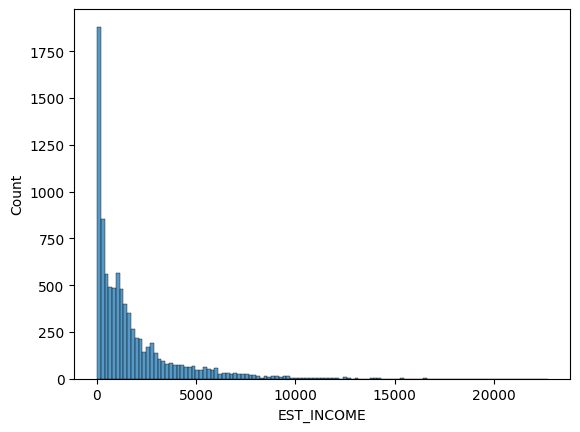

In [8]:
sns.histplot(data=df['EST_INCOME'])

Suponemos que una división razonable es entre los que tienen este valor menor a 1000, los que lo tienen mayor a 1000 y menor a 5000 y los mayores a 5000. Los llamamos categorías 0,1 y 2.

In [10]:
rangos = [
    df['EST_INCOME'] <= 1000,
    (df['EST_INCOME'] > 1000) & (df['EST_INCOME'] <= 5000),
    df['EST_INCOME'] > 5000
]

categorias = [0, 1, 2]

df['CATEGORY'] = np.select(rangos, categorias)
df['CATEGORY'] = df['CATEGORY'].astype('category')

In [18]:
df_filtered = df[['BALANCE_FREQUENCY','PURCHASES_FREQUENCY','ONEOFF_PURCHASES_FREQUENCY','PURCHASES_INSTALLMENTS_FREQUENCY','CASH_ADVANCE_FREQUENCY','PRC_FULL_PAYMENT','AVG_PURCHASES','AVG_INSTALLMENTS_PURCHASES','AVG_ONEOFF_PURCHASES','AVG_PURCHASES_TRX','AVG_PURCHASE_COST','AVG_CASH_ADVANCE_TRX','CATEGORY']]

c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Lenny\Python39\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_i

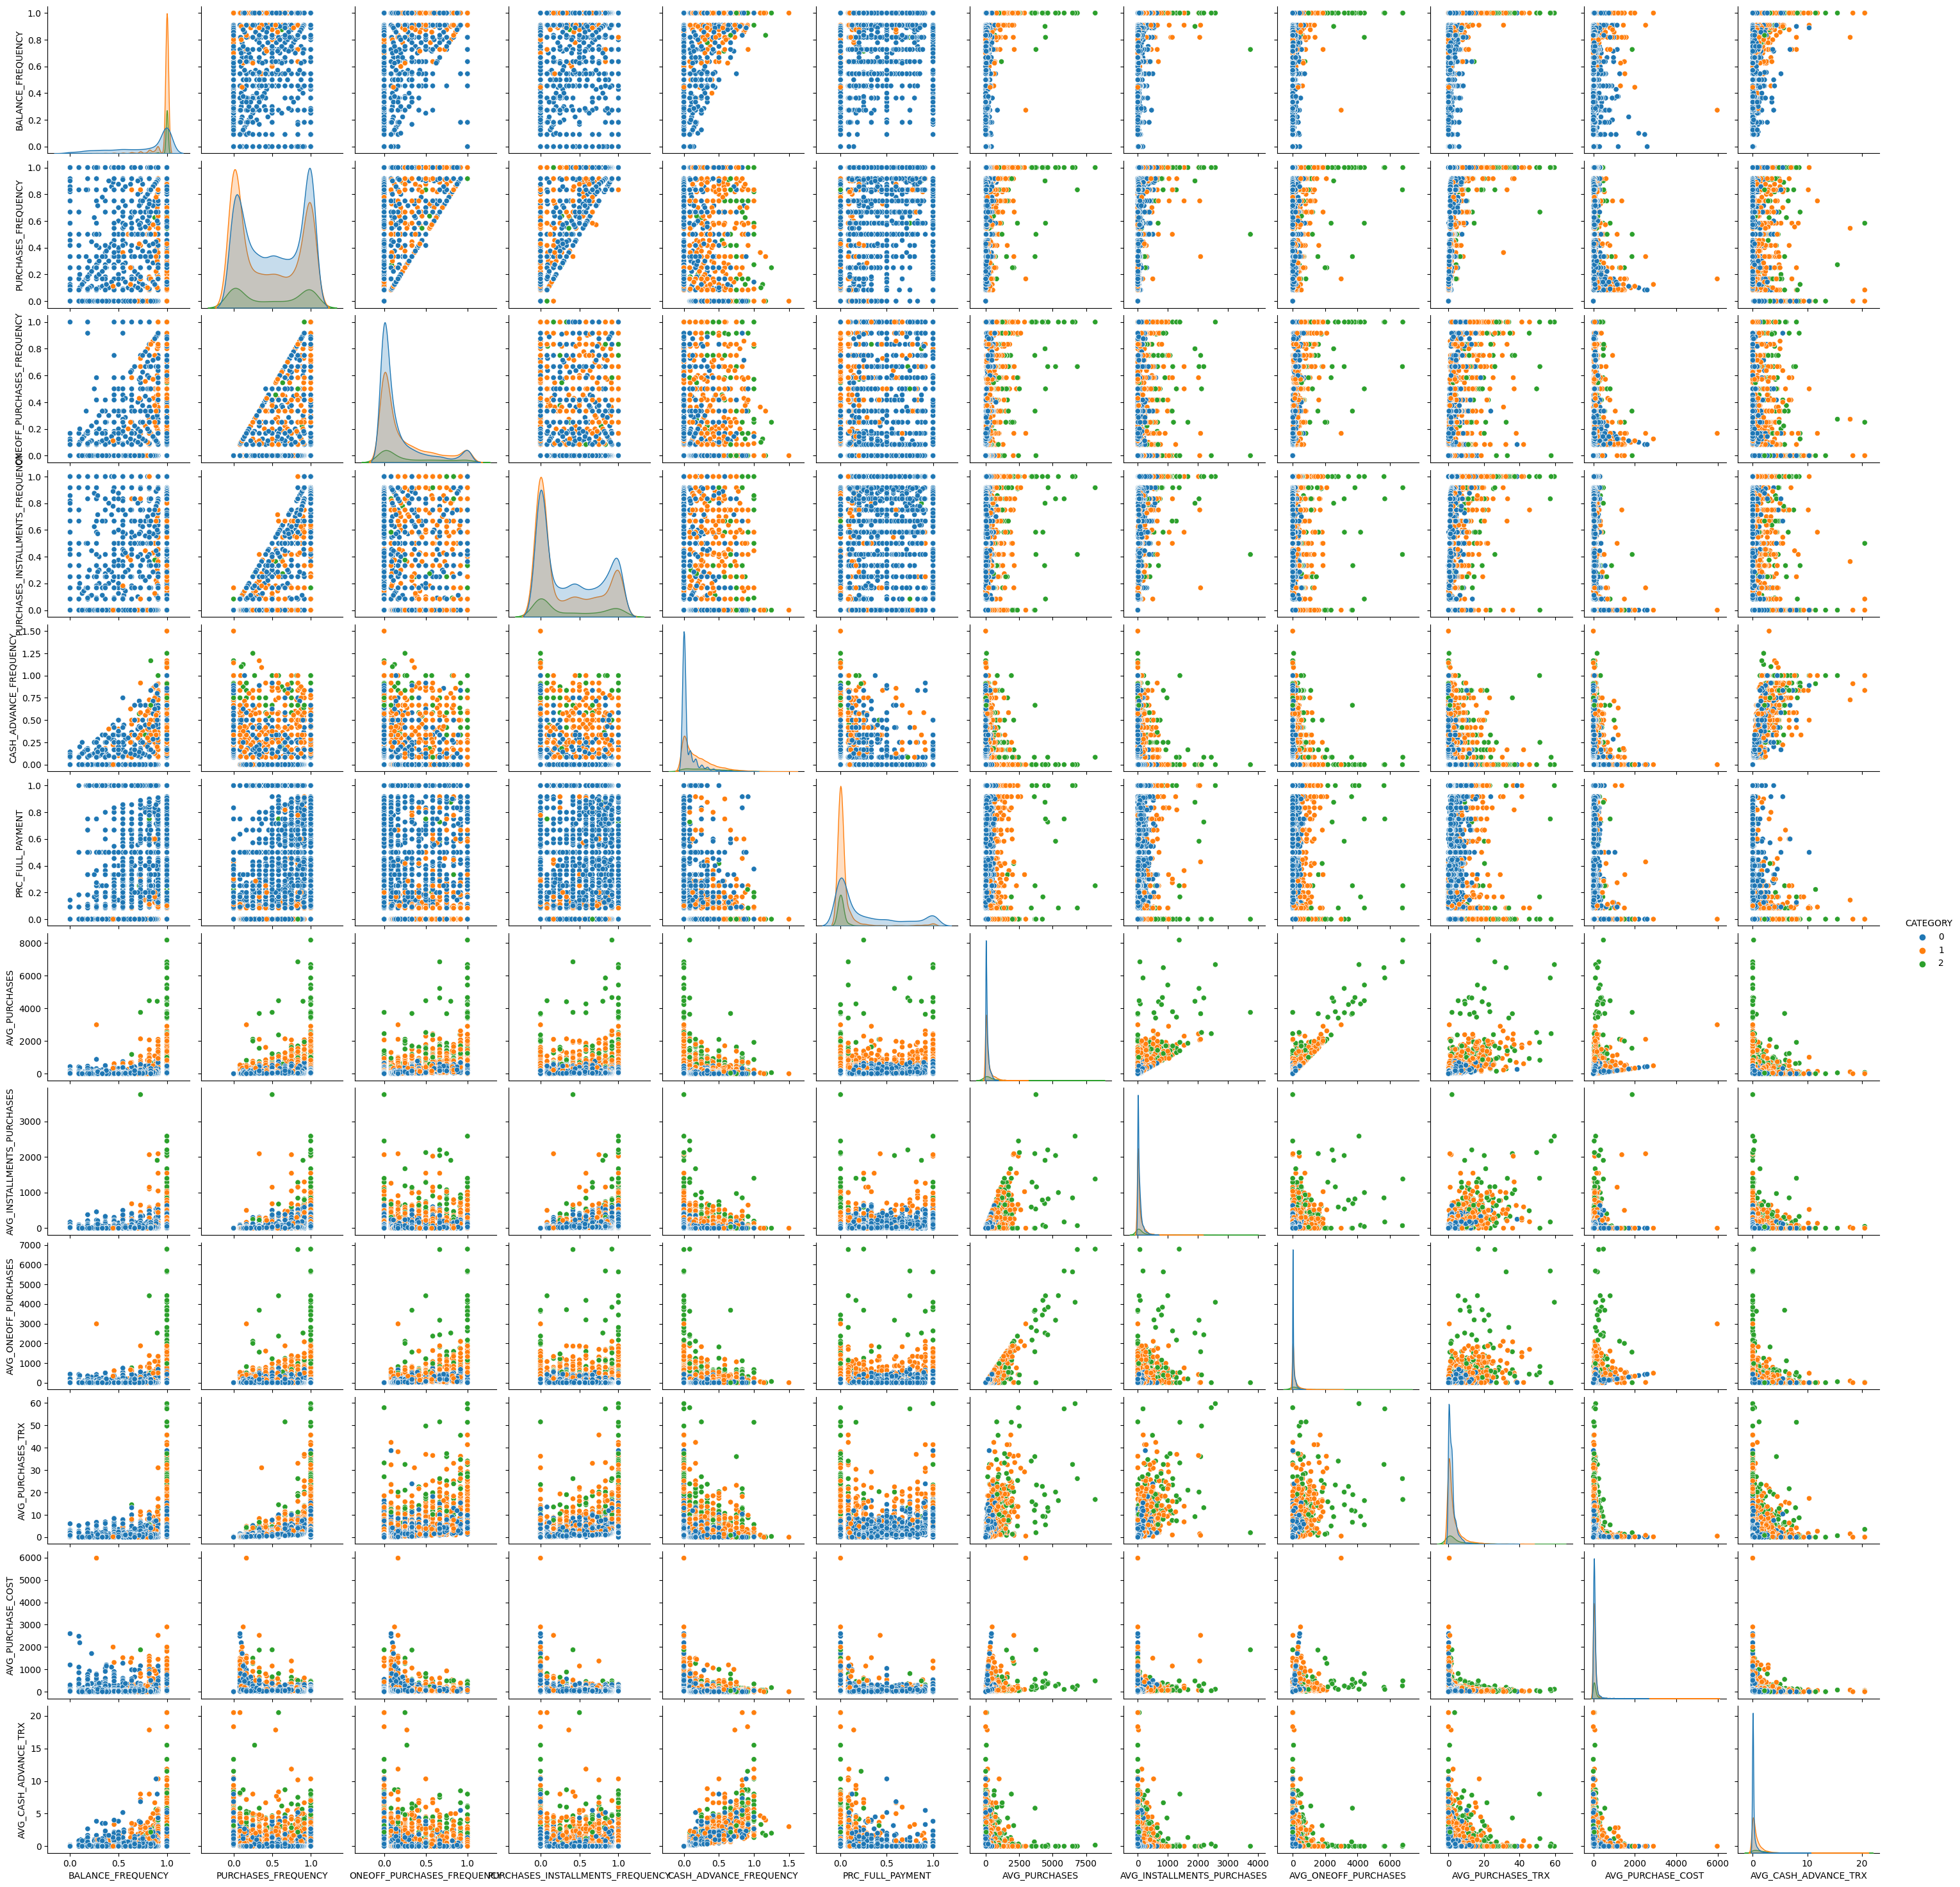

In [19]:
sns.pairplot(df_filtered,hue='CATEGORY')

En los scatter plots no observamos separaciones claras de categorías, más allá de los esperables para las diferencias de recursos (por ejemplo, que quienes más tienen gastan más, no suelen pedir adelantos de efectivo y no tienen problemas para pagarlos). En la distribución de purchases frequency notamos que las tres categorías comparten una diversidad de valores pero con dos picos en los bajos y en los altos. En otras palabras, la gente suele comprar poco o mucho, más que cantidades intermedias de compras. En resumen, no parece razonable dividir a los usuarios en clusters sólo por cuánto dinero tienen.

Comenzamos a pensar con qué criterios armamos los clusters. Las variables con mayor diversidad, que por lo tanto tienen mayor potencial para dividir a los usuarios en grupos, son purchases_frequency y sus variantes installment y oneoff. Sin embargo, habíamos notado que estas dos últimas están acotadas superiormente por la anterior, por lo que hay cierta redundancia. Con algo de diversidad pero más concentrados aparecen balance frequency, cash advance frequency y prc full payment.